# 03 · Modelling, Evaluation and Model Saving

**Goal.** Build, compare and tune classification models that predict diabetes, evaluate the best one on unseen data, and save it.

**Workflow:** 1. Setup and data · 2. Preprocessing pipeline · 3. Cross-validation · 4. Class imbalance · 5. Hyperparameter tuning · 6. Final evaluation on the test set · 7. Feature importance · 8. Save the model

> **Rule followed in this notebook:** all model selection uses the *training set only* (cross-validation). The test set is used **once**, in section 6.

## 1. Setup and data

In [2]:
# Imports, seed and paths
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
PROCESSED_DIR = Path("../data/processed")

In [3]:
# Reload the train/test sets saved by notebook 02 and split features from target
train = pd.read_csv(PROCESSED_DIR / "train.csv")
test = pd.read_csv(PROCESSED_DIR / "test.csv")

X_train = train.drop(columns="Diabetes_Outcome")
y_train = train["Diabetes_Outcome"]
X_test = test.drop(columns="Diabetes_Outcome")
y_test = test["Diabetes_Outcome"]

print(X_train.shape, X_test.shape)

(400, 8) (100, 8)


## 2. Preprocessing pipeline
- **Numeric features** → `StandardScaler` (mean 0, standard deviation 1). This matters for KNN, SVM and logistic regression.
- **Categorical features** (`Gender`, `Family_History`) → `OneHotEncoder(drop="if_binary")`, i.e. a single 0/1 column each.

The `ColumnTransformer` is placed inside a `Pipeline`, so during cross-validation it is re-fitted on the training folds only. This prevents data leakage.

In [4]:
# Column lists and the ColumnTransformer that scales numeric and encodes categorical features
num_features = ["Age", "BMI", "Glucose_Level", "Blood_Pressure", "Insulin", "Physical_Activity"]
cat_features = ["Gender", "Family_History"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat_features),
])
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

## 3. Cross-validation: comparing models
`StratifiedKFold` with 5 folds keeps the class proportions in every fold. Six models are compared with five metrics:


In [4]:
# 5-fold stratified cross-validation of 6 models, each wrapped in preprocessing + classifier
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "SVM (RBF)": SVC(probability=True, random_state=RANDOM_STATE),
}
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("clf", model)])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    row = {"Modèle": name}
    for m in scoring:
        row[m] = res[f"test_{m}"].mean()
    rows.append(row)

cv_results = pd.DataFrame(rows).set_index("Modèle").sort_values("f1", ascending=False)
cv_results.round(3)

,accuracy,precision,recall,f1,roc_auc
Modèle,,,,,
Gradient Boosting,0.992,0.995,0.991,0.993,0.992
Decision Tree,0.992,0.995,0.991,0.993,0.993
Random Forest,0.988,0.982,0.995,0.989,0.998
SVM (RBF),0.895,0.888,0.926,0.905,0.971
Logistic Regression,0.893,0.901,0.908,0.901,0.976
KNN,0.792,0.777,0.866,0.819,0.896


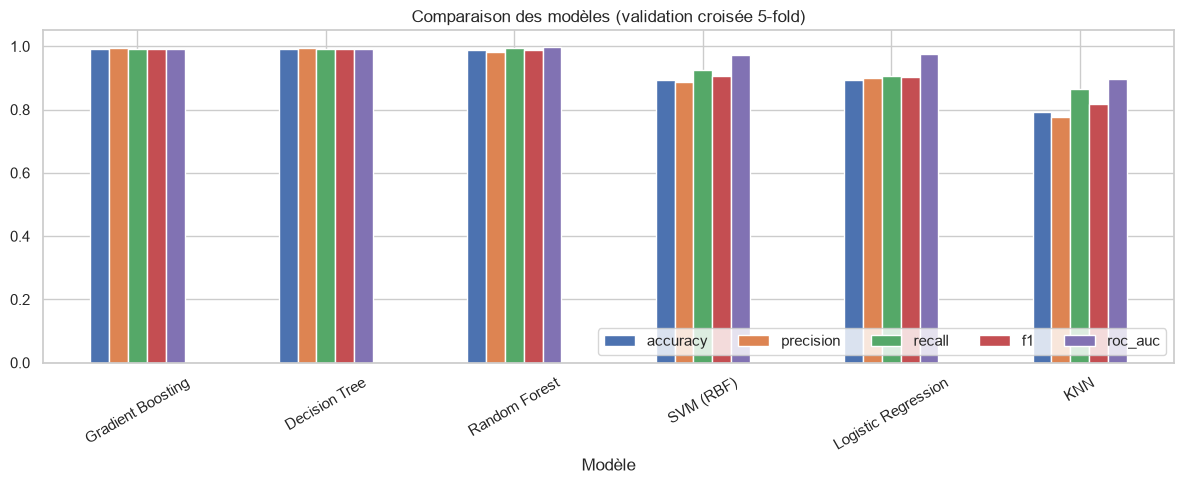

In [5]:
# Bar chart comparing the cross-validated scores of all models
cv_results.plot(kind="bar", figsize=(12, 5), rot=30)
plt.title("Comparaison des modèles (validation croisée 5-fold)")
plt.ylim(0, 1.05)
plt.legend(loc="lower right", ncol=5)
plt.tight_layout()
plt.show()

## 4. Handling class imbalance
The classes are almost balanced (54/46), but three strategies are compared on a Random Forest to check whether a correction helps:
1. no correction,
2. `class_weight="balanced"` (re-weights the classes during training),
3. **SMOTE** (creates synthetic samples of the minority class).

SMOTE comes from `imbalanced-learn` and is placed *inside* the pipeline, so it is applied to training folds only, never to validation or test data.

In [6]:
# Imports for imbalance handling (pipeline that supports resampling, and SMOTE)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

In [7]:
# Compare the three strategies with the same cross-validation
strategies = {
    "Sans correction": Pipeline([
        ("prep", preprocessor),
        ("clf", RandomForestClassifier(random_state=RANDOM_STATE))]),
    "class_weight='balanced'": Pipeline([
        ("prep", preprocessor),
        ("clf", RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE))]),
    "SMOTE": ImbPipeline([
        ("prep", preprocessor),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("clf", RandomForestClassifier(random_state=RANDOM_STATE))]),
}

rows = []
for name, pipe in strategies.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({"Stratégie": name, **{m: res[f"test_{m}"].mean() for m in scoring}})

imbalance_results = pd.DataFrame(rows).set_index("Stratégie")
imbalance_results.round(3)

,accuracy,precision,recall,f1,roc_auc
Stratégie,,,,,
Sans correction,0.988,0.982,0.995,0.989,0.998
class_weight='balanced',0.988,0.982,0.995,0.989,0.999
SMOTE,0.992,0.991,0.995,0.993,0.998


## 5. Hyperparameter tuning
`GridSearchCV` tries every combination of the grid below with 5-fold cross-validation and keeps the one with the best **F1-score**. Best parameters found: `max_depth=5`, `min_samples_leaf=1`, `n_estimators=100` (cross-validated F1 ≈ 0.991).

In [8]:
# Grid search over Random Forest hyperparameters (parameter names use the pipeline prefix clf__)
from sklearn.model_selection import GridSearchCV

pipe_rf = Pipeline([
    ("prep", preprocessor),
    ("clf", RandomForestClassifier(random_state=RANDOM_STATE))])

param_grid = {
    "clf__n_estimators": [100, 300],
    "clf__max_depth": [None, 5, 10],
    "clf__min_samples_leaf": [1, 3, 5],
}

grid = GridSearchCV(pipe_rf, param_grid, cv=cv, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)

print("Meilleurs paramètres :", grid.best_params_)
print("Meilleur F1 (CV)     :", round(grid.best_score_, 3))
best_model = grid.best_estimator_

Meilleurs paramètres : {'clf__max_depth': 5, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 100}
Meilleur F1 (CV)     : 0.991


## 6. Final evaluation on the test set
This is the **first and only** use of the test set. The model has never seen these 100 patients.

In [9]:
# Metric imports, then predicted classes and predicted probabilities of the positive class
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, RocCurveDisplay)

y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

In [10]:
# Compute the metrics on the test set and print a per-class report
final = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1-score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_proba),
})
print(final.round(3))
print()
print(classification_report(y_test, y_pred, target_names=["Non diabétique", "Diabétique"]))

Accuracy     0.980
Precision    0.964
Recall       1.000
F1-score     0.982
ROC-AUC      1.000
dtype: float64

                precision    recall  f1-score   support

Non diabétique       1.00      0.96      0.98        46
    Diabétique       0.96      1.00      0.98        54

      accuracy                           0.98       100
     macro avg       0.98      0.98      0.98       100
  weighted avg       0.98      0.98      0.98       100



### Confusion matrix
|  | Predicted non-diabetic | Predicted diabetic |
|---|---|---|
| **Actual non-diabetic** | TN (correct) | FP (false alarm) |
| **Actual diabetic** | FN (missed case) | TP (correct) |

In a medical setting a **false negative** (a diabetic patient missed) is the most serious error, which is why recall is monitored closely. Result on the test set: TN = 44, FP = 2, FN = 0, TP = 54.

TN=44 | FP=2 | FN=0 | TP=54


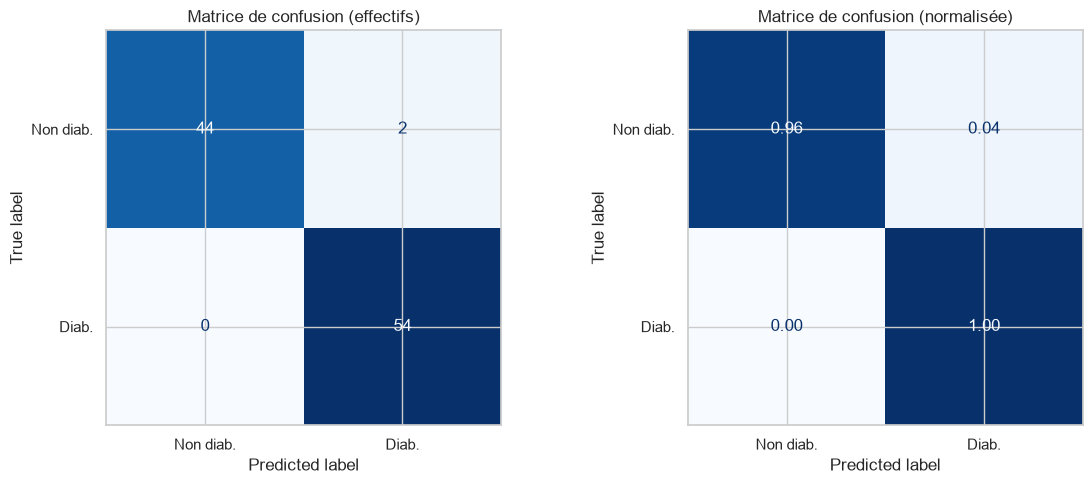

In [11]:
# Confusion matrix as counts (left) and normalized by row (right)
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn} | FP={fp} | FN={fn} | TP={tp}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(cm, display_labels=["Non diab.", "Diab."]).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Matrice de confusion (effectifs)")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, normalize="true", display_labels=["Non diab.", "Diab."],
    ax=axes[1], cmap="Blues", colorbar=False, values_format=".2f")
axes[1].set_title("Matrice de confusion (normalisée)")
plt.tight_layout()
plt.show()

### ROC curve
The closer the curve is to the top-left corner, the better the model separates the two classes. The dashed line is a random classifier (AUC = 0.5).

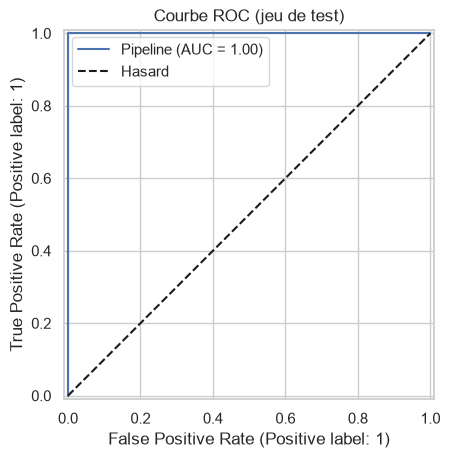

In [12]:
# ROC curve of the best model on the test set
RocCurveDisplay.from_estimator(best_model, X_test, y_test)
plt.plot([0, 1], [0, 1], "k--", label="Hasard")
plt.legend()
plt.title("Courbe ROC (jeu de test)")
plt.show()

### Overfitting check
A large gap between the cross-validated score and the test score would signal overfitting. Here the gap is small (F1 0.991 vs 0.982).

In [13]:
# Compare the cross-validated F1 with the test F1
print(f"F1 en validation croisée : {grid.best_score_:.3f}")
print(f"F1 sur le test           : {final['F1-score']:.3f}")
print("Écart :", round(abs(grid.best_score_ - final['F1-score']), 3))


F1 en validation croisée : 0.991
F1 sur le test           : 0.982
Écart : 0.009


## 7. Feature importance
**Permutation importance** shuffles one feature at a time on the test set and measures how much the F1-score drops. The bigger the drop, the more the model relies on that feature. The three key features are `Family_History`, `BMI` and `Glucose_Level`; the other features are close to 0, meaning the model does not use them.

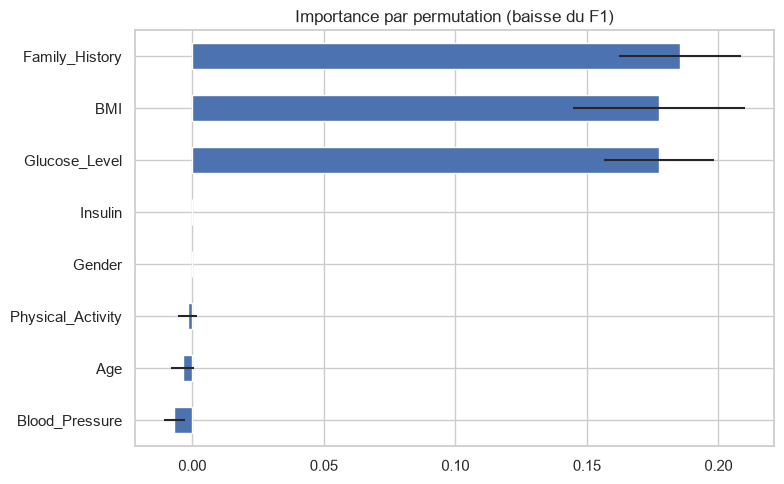

In [14]:
# Permutation importance with its standard deviation over 20 repeats
from sklearn.inspection import permutation_importance

perm = permutation_importance(best_model, X_test, y_test, n_repeats=20,
                              scoring="f1", random_state=RANDOM_STATE, n_jobs=-1)

imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
err = pd.Series(perm.importances_std, index=X_test.columns)[imp.index]

imp.plot(kind="barh", xerr=err, figsize=(8, 5))
plt.title("Importance par permutation (baisse du F1)")
plt.tight_layout()
plt.show()

## 8. Save the model
The saved object is the whole pipeline (preprocessing + Random Forest), so it accepts raw patient data. It is reloaded and tested on a new patient as a sanity check.

In [15]:
# Save the pipeline with joblib, reload it, and predict for one example patient
import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)
joblib.dump(best_model, MODEL_DIR / "best_diabetes_model.joblib")

loaded = joblib.load(MODEL_DIR / "best_diabetes_model.joblib")
new_patient = pd.DataFrame([{
    "Age": 55, "Gender": "M", "BMI": 32.0, "Glucose_Level": 170,
    "Blood_Pressure": 120, "Insulin": 200.0, "Physical_Activity": 30,
    "Family_History": "Yes"}])

print("Prédiction :", loaded.predict(new_patient)[0])
print("Probabilité de diabète :", round(loaded.predict_proba(new_patient)[0, 1], 3))

Prédiction : 1
Probabilité de diabète : 0.97


## Summary of results

| Item | Value |
|---|---|
| Best model | Random Forest (`max_depth=5`, `n_estimators=100`) |
| Cross-validated F1 | 0.991 |
| Test Accuracy / Precision / Recall / F1 | 0.98 / 0.964 / 1.00 / 0.982 |
| Confusion matrix (test) | TN = 44, FP = 2, FN = 0, TP = 54 |
| Key features | `Family_History`, `BMI`, `Glucose_Level` |

**Limitations.** The dataset is small (500 patients) and most likely synthetic: simple tree models reach about 99% in cross-validation, which suggests the target follows threshold rules on a few variables. Scores on real clinical data would be lower. The test set contains only 100 patients, so each error weighs 1% of accuracy.

**Possible improvements.** Validate on real data, add more clinical variables, and have the thresholds reviewed by a medical expert.